# Fisher matrix with the LISA response

This example computes a full Fisher matrix for an EMRI as seen through the LISA detector response, then plots the resulting parameter covariances as error ellipses. It covers:

1. Setting up a FEW waveform model (`FastSchwarzschildEccentricFlux`) and wrapping it in the LISA time-delay interferometry (TDI) response from `fastlisaresponse`.
2. Choosing a noise model: the LISA PSDs of the A and E TDI channels from `lisatools`.
3. Computing the signal-to-noise ratio (SNR) of the source.
4. Computing the Fisher matrix over 11 parameters with stable numerical derivatives.
5. Inverting it to get the covariance matrix, and plotting the $1\sigma$, $2\sigma$ and $3\sigma$ ellipses.

**Requirements:** `lisaanalysistools` and `fastlisaresponse`, for the LISA response and noise model (see the installation guide). The notebook is set to `use_gpu = True`; set it to `False` to run on a CPU (slower).

*Validated with LISAAnalysisTools-cuda12x v1.2.0 and fastlisaresponse v1.1.17.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from few.waveform import GenerateEMRIWaveform, FastSchwarzschildEccentricFlux

# Set use_gpu = False to run on a CPU
use_gpu = False

from stableemrifisher.fisher.fisher import StableEMRIFisher
from stableemrifisher.utils import inner_product

from fastlisaresponse import ResponseWrapper  # Response function 
from lisatools.detector import EqualArmlengthOrbits
from lisatools.sensitivity import get_sensitivity, A1TDISens, E1TDISens

# On a CPU, restrict FEW to its CPU backend
if not use_gpu:
    
    import few
    
    #tune few configuration
    cfg_set = few.get_config_setter(reset=True)
    
    cfg_set.enable_backends("cpu")
    cfg_set.set_log_level("info");
    force_backend = 'cpu'
else:
    pass #let the backend decide for itself.

/Users/skejriwal/miniconda3/envs/sefv1/lib/python3.12/site-packages/lisaconstants/compat/astropy.py:252: UserWarning: The following constants differ between lisaconstants and the version of astropy you have installed: VACUUM_PERMEABILITY. The recommended version of astropy is 7.2.0. Use a different one at your own risks. 
You may also open an issue at https://gitlab.esa.int/lisa-sgs/commons/lisa-constants to warn that lisaconstants is not compatible with astropy v8.0.2
  warnings.warn(


startup


## Set up the waveform, response and noise model

`StableEMRIFisher` takes the waveform and response *classes* together with their keyword arguments, rather than ready-made objects, so that it can build the waveform and derivative generators itself.

- **Waveform:** `return_list=False` makes the generator return $h_+ - i h_\times$ as a single complex array, which SEF requires.
- **Response:** first-generation TDI on equal-arm-length orbits, returning the A and E channels. `index_lambda` and `index_beta` tell the response which waveform arguments hold the sky position (`phiS` and `qS`).
- **Noise:** one PSD per TDI channel, from `get_sensitivity` with the matching `sens_fn`.

In [2]:
#waveform class setup
waveform_class = FastSchwarzschildEccentricFlux
# mode_selection_threshold: drop modes that contribute less than this fraction of the total power
waveform_class_kwargs = dict(inspiral_kwargs=dict(err=1e-11,),
                             mode_selector_kwargs=dict(mode_selection_threshold=1e-5))

#waveform generator setup
waveform_generator = GenerateEMRIWaveform
waveform_generator_kwargs = dict(return_list=False)

#ResponseWrapper setup
ResponseWrapper = ResponseWrapper
tdi_gen ="1st generation"# "2nd generation"#
order = 20  # interpolation order (should not change the result too much)
tdi_kwargs_esa = dict(
    orbits=EqualArmlengthOrbits(), order=order, tdi=tdi_gen, tdi_chan="AE",
)  # could do "AET"
index_lambda = 8
index_beta = 7
# with longer signals we care less about this
t0 = 10000.0  # throw away on both ends when our orbital information is weird
# Observation time (years) and sampling interval (seconds)
T = 0.1
dt = 10.0

ResponseWrapper_kwargs = dict(
    #waveform_gen=waveform_generator,
    Tobs = T,
    dt = dt,
    index_lambda = index_lambda,
    index_beta = index_beta,
    t0 = t0,
    flip_hx = True,
    is_ecliptic_latitude=False,
    remove_garbage="zero",
    **tdi_kwargs_esa
)

#noise setup
channels = [A1TDISens, E1TDISens]
noise_model = get_sensitivity
# Keyword arguments passed to the noise model, one dictionary per channel
noise_kwargs = [{"sens_fn": channel_i} for channel_i in channels]

## Initialise StableEMRIFisher

`deriv_type='stable'` uses SEF's stable derivative scheme, and `stats_for_nerds=True` turns on detailed logging, including the step-size search below.

In [3]:
sef = StableEMRIFisher(waveform_class=waveform_class, 
                       waveform_class_kwargs=waveform_class_kwargs,
                       waveform_generator=waveform_generator,
                       waveform_generator_kwargs=waveform_generator_kwargs,
                       ResponseWrapper=ResponseWrapper, ResponseWrapper_kwargs=ResponseWrapper_kwargs,
                       noise_model=noise_model, noise_kwargs=noise_kwargs, channels=channels,
                      stats_for_nerds = True, use_gpu = use_gpu,
                       T=T, dt=dt,
                      deriv_type='stable')

## Signal-to-noise ratio

Check the SNR of the source first. The Fisher matrix only approximates the posterior well at high SNR; SEF warns if the SNR is 20 or below.

In [4]:
# Source parameters: masses (solar masses), spin, initial semi-latus rectum and eccentricity, inclination, distance (Gpc), sky and spin angles, and initial phases
m1 = 1e6
m2 = 1e1
a = 0.
p0 = 9.5
e0 = 0.4
xI0 = 1.0
dist = 0.1
qS = np.pi/3
phiS = np.pi/4
qK = np.pi/6
phiK = np.pi/8
Phi_phi0 = 1.0
Phi_theta0 = 0.0
Phi_r0 = 0.0

pars_list = [m1, m2, a, p0, e0, xI0, dist, qS, phiS, qK, phiK, Phi_phi0, Phi_theta0, Phi_r0]

emri_kwargs = {"T":T, "dt":dt}

# Generate the waveform and PSDs, and return the optimal SNR
sef.SNRcalc_SEF(*pars_list,**emri_kwargs, use_gpu=use_gpu)

waveform shape: (2, 315581)
wave ndim: 2
Computing SNR for parameters: (1000000.0, 10.0, 0.0, 9.5, 0.4, 1.0, 0.1, 1.0471975511965976, 0.7853981633974483, 0.5235987755982988, 0.39269908169872414, 1.0, 0.0, 0.0)


np.float64(237.8360125152412)

## Compute the Fisher matrix

- `param_names`: the parameters in the Fisher matrix, in order. The spin `a` is left out because this Schwarzschild model has no spin, and `xI0` and `Phi_theta0` because the orbit is equatorial.
- `der_order`: the order of the finite-difference stencil.
- `Ndelta` and `delta_range`: for each parameter, SEF tries `Ndelta` step sizes (from `delta_range`, or a default grid for parameters not listed) and keeps the one where the diagonal Fisher element is most stable. `stability_plot=True` plots this search.
- `live_dangerously=False` keeps the stability search on. `True` skips it and uses rough heuristic step sizes instead.

Body is not plunging, Fisher should be stable.
waveform shape: (2, 315581)
wave ndim: 2
Computing SNR for parameters: (1000000.0, 10.0, 0.0, 9.5, 0.4, 1.0, 0.1, 1.0471975511965976, 0.7853981633974483, 0.5235987755982988, 0.39269908169872414, 1.0, 0.0, 0.0)
Waveform Generated. SNR: 237.8360125152412
calculating stable deltas...
Gamma_ii for m1: 117.54186243264293
Gamma_ii for m1: 117.54186243220703
Gamma_ii for m1: 117.54186243352281
Gamma_ii for m1: 117.54186246186003
Gamma_ii for m1: 117.54186225746328
Gamma_ii for m1: 117.54186210144769
Gamma_ii for m1: 117.54186616564067
Gamma_ii for m1: 117.54187847836535
[np.float64(3.708497964165885e-12), np.float64(1.119416530280614e-11), np.float64(2.410819882007314e-10), np.float64(1.7389273199812401e-09), np.float64(1.3273193500168668e-09), np.float64(3.457655651711453e-08), np.float64(1.0475181133267645e-07)]
0


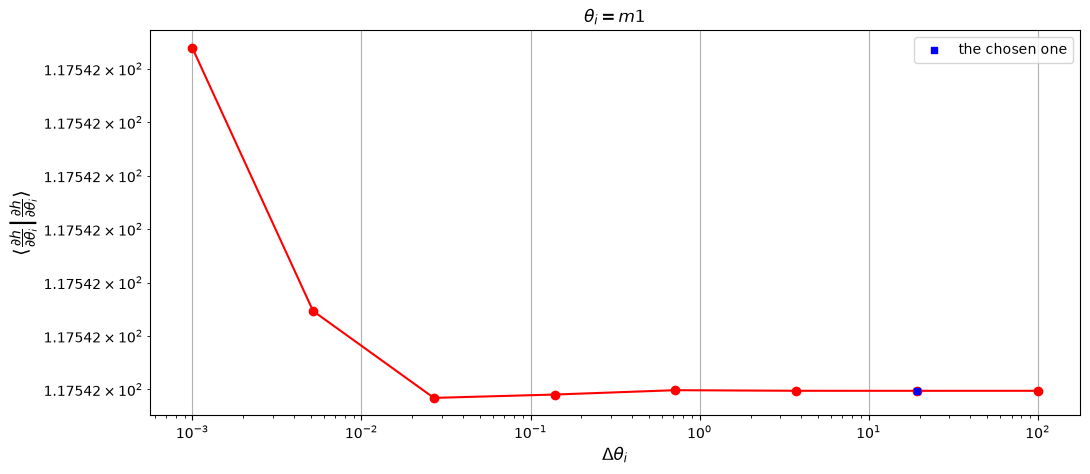

Gamma_ii for m2: 131924254.54387861
Gamma_ii for m2: 131924254.53133604
Gamma_ii for m2: 131924254.53278616
Gamma_ii for m2: 131924254.52818277
Gamma_ii for m2: 131924254.66409552
Gamma_ii for m2: 131924254.02687696
Gamma_ii for m2: 131924262.49025966
Gamma_ii for m2: 131924206.64324164
[np.float64(9.507406839114499e-11), np.float64(1.0992075777696288e-11), np.float64(3.4894159089673343e-11), np.float64(1.0302331935631148e-09), np.float64(4.830185089535874e-09), np.float64(6.415334485323334e-08), np.float64(4.2332654059000854e-07)]
1


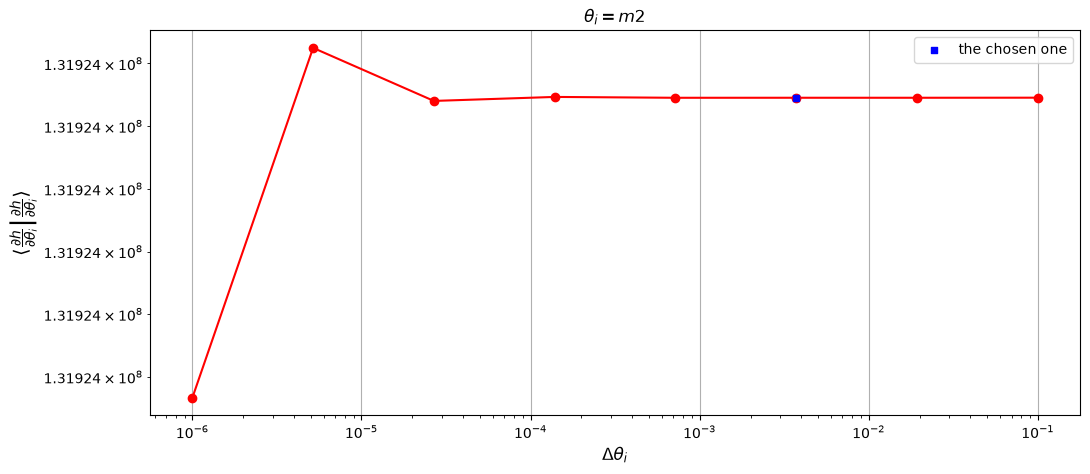

Gamma_ii for p0: 2100666224333.3894
Gamma_ii for p0: 2100667474492.1914
Gamma_ii for p0: 2100667702530.8577
Gamma_ii for p0: 2100667806617.826
Gamma_ii for p0: 2100668255145.5151
Gamma_ii for p0: 2100668917008.9294
Gamma_ii for p0: 2100646488813.639
Gamma_ii for p0: 2100534427466.52
[np.float64(5.9512455787614e-07), np.float64(1.0855532552103674e-07), np.float64(4.9549466095405e-08), np.float64(2.1351666933145255e-07), np.float64(3.150726937251232e-07), np.float64(1.067680612133548e-05), np.float64(5.334896950680072e-05)]
2


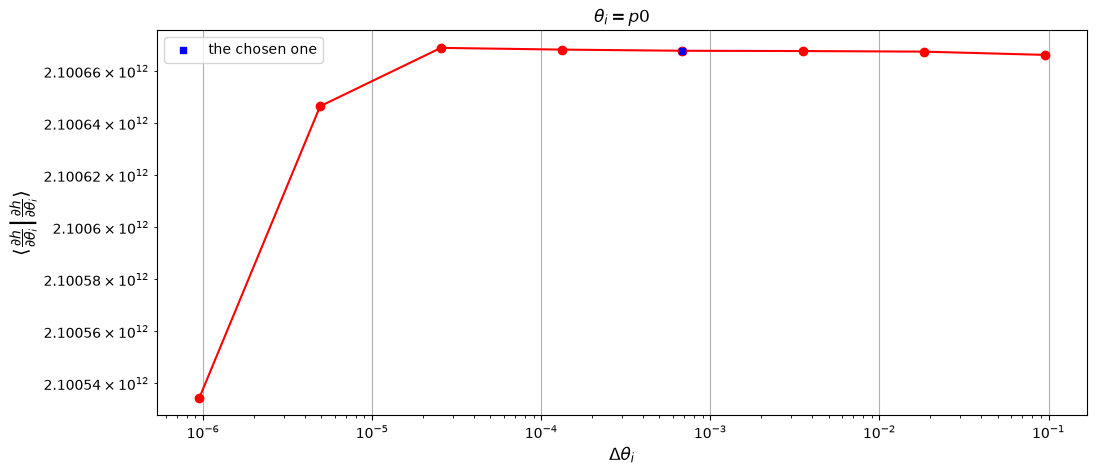

Gamma_ii for e0: 113246009969297.67
Gamma_ii for e0: 113245409915603.48
Gamma_ii for e0: 113245437697605.62
Gamma_ii for e0: 113245429414848.44
Gamma_ii for e0: 113245455612544.5
Gamma_ii for e0: 113245603411341.78
Gamma_ii for e0: 113245956353347.19
Gamma_ii for e0: 113217344249349.77
[np.float64(5.298702125187166e-06), np.float64(2.453255751883804e-07), np.float64(7.313988061414854e-08), np.float64(2.3133551735737828e-07), np.float64(1.3051173098914994e-06), np.float64(3.1165969785712193e-06), np.float64(0.0002527183815088138)]
2


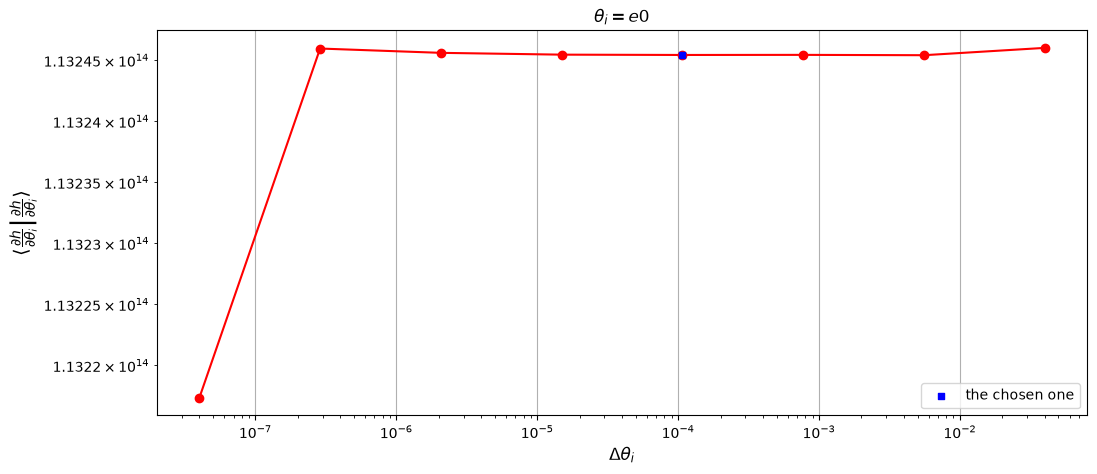

Gamma_ii for qS: 904913.0683922166
Gamma_ii for qS: 873852.0985558305
Gamma_ii for qS: 874424.0341770481
Gamma_ii for qS: 874507.6257491886
Gamma_ii for qS: 874494.9159641782
Gamma_ii for qS: 874491.6910583585
Gamma_ii for qS: 874490.6546441399
Gamma_ii for qS: 874533.9153530932
[np.float64(0.0355448821233237), np.float64(0.0006540712501753921), np.float64(9.558701339950833e-05), np.float64(1.4533858091581465e-05), np.float64(3.6877489547432432e-06), np.float64(1.1851632868765094e-06), np.float64(4.946715981367905e-05)]
5


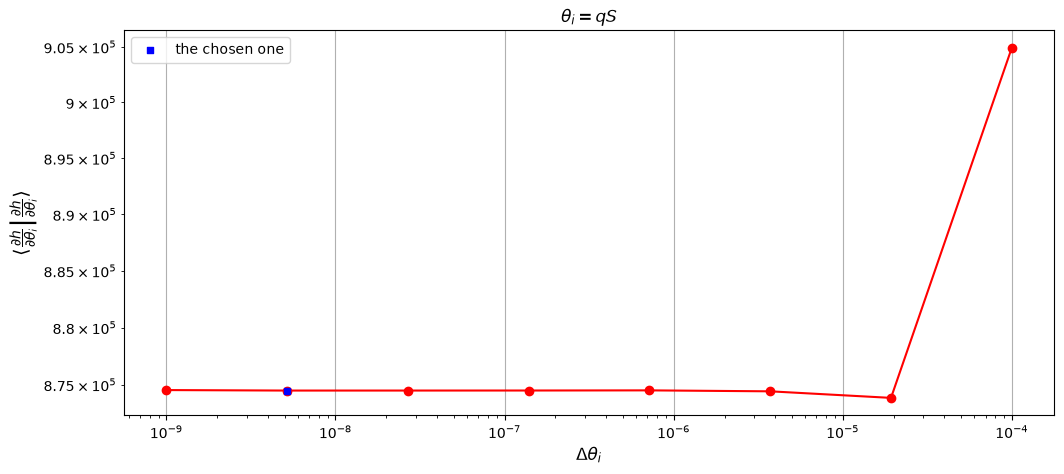

Gamma_ii for phiS: 595945.9660934741
Gamma_ii for phiS: 596005.7565978058
Gamma_ii for phiS: 596391.6534772873
Gamma_ii for phiS: 596408.5892034466
Gamma_ii for phiS: 596382.5432919911
Gamma_ii for phiS: 596387.1163082207
Gamma_ii for phiS: 596391.2149983076
Gamma_ii for phiS: 596394.7862998934
[np.float64(0.00010031866919038518), np.float64(0.0006470527835718568), np.float64(2.8396180849755558e-05), np.float64(4.367316204755975e-05), np.float64(7.66786555997278e-06), np.float64(6.8724856837257816e-06), np.float64(5.988150245106307e-06)]
6


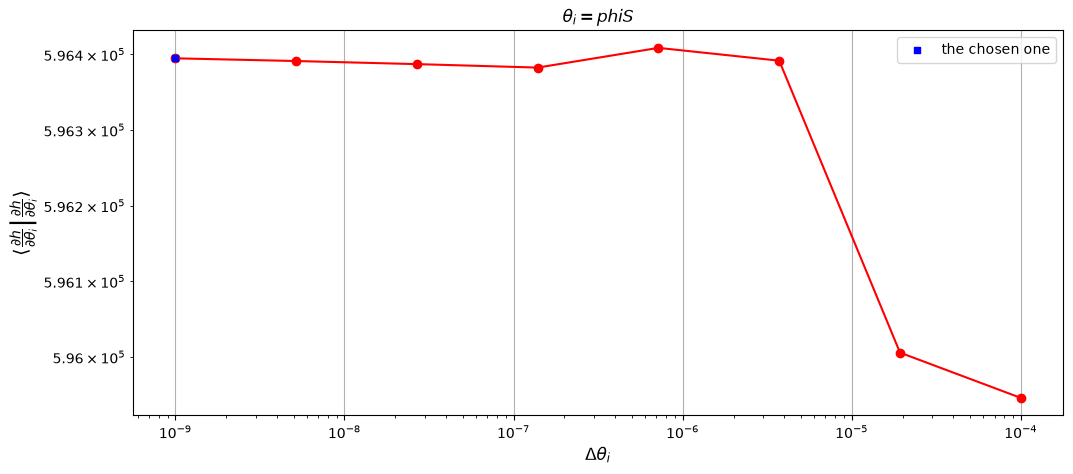

Gamma_ii for qK: 289771.3795174796
Gamma_ii for qK: 289771.37951460015
Gamma_ii for qK: 289771.3795424888
Gamma_ii for qK: 289771.3796545783
Gamma_ii for qK: 289771.3793066558
Gamma_ii for qK: 289771.37937218783
Gamma_ii for qK: 289771.38054029853
Gamma_ii for qK: 289771.3409570791
[np.float64(9.937057215767013e-12), np.float64(9.624355988460887e-11), np.float64(3.868204762818359e-10), np.float64(1.2006793035499192e-09), np.float64(2.2615086225392965e-10), np.float64(4.031145852807036e-09), np.float64(1.36601567695984e-07)]
0


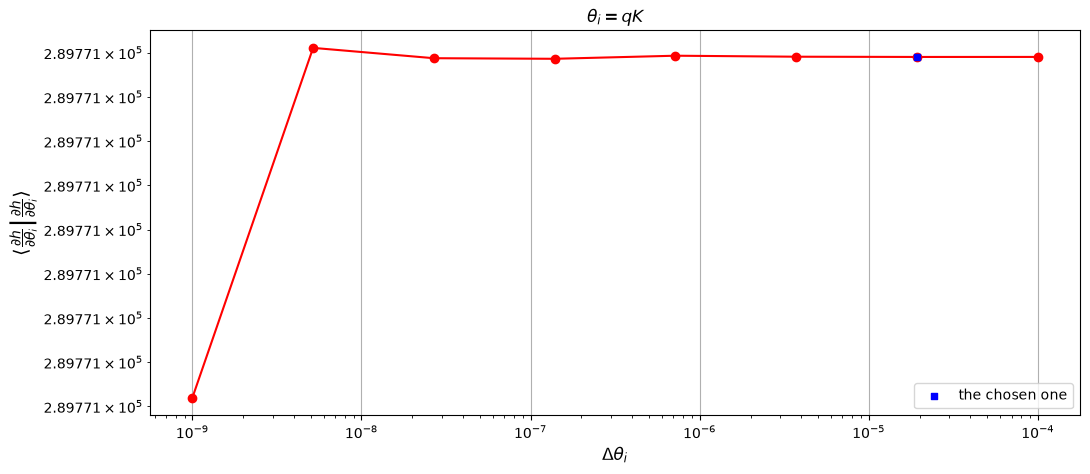

Gamma_ii for phiK: 121444.92305744032
Gamma_ii for phiK: 121444.92305741641
Gamma_ii for phiK: 121444.92304887784
Gamma_ii for phiK: 121444.92309673544
Gamma_ii for phiK: 121444.92325297161
Gamma_ii for phiK: 121444.9232050934
Gamma_ii for phiK: 121444.93259666784
Gamma_ii for phiK: 121444.92039537148
[np.float64(1.9686946245503568e-13), np.float64(7.030816008217481e-11), np.float64(3.940683186670215e-10), np.float64(1.286477590031747e-09), np.float64(3.942381077420521e-10), np.float64(7.733195819863334e-08), np.float64(1.0046773738737078e-07)]
0


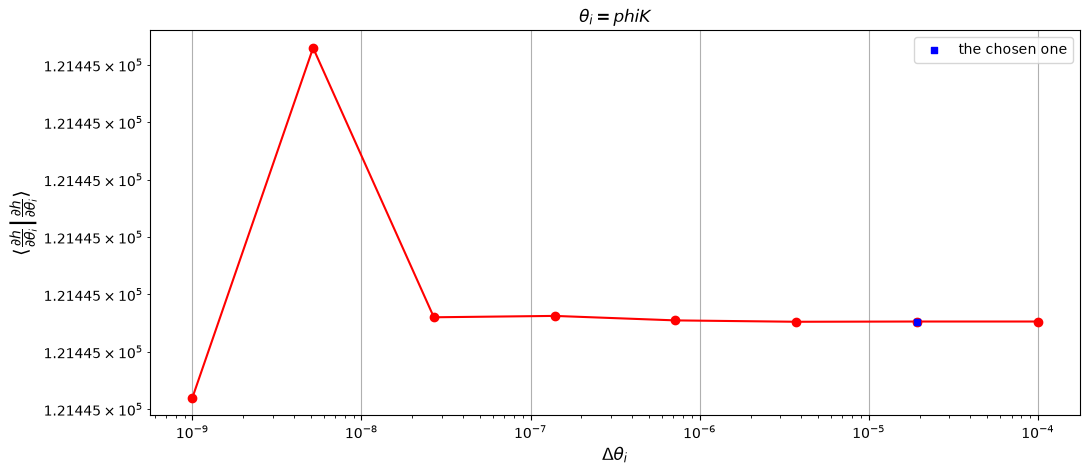

stable deltas: {'m1': 19.306977288832496, 'm2': 0.003727593720314938, 'p0': 0.000683701389351095, 'e0': 0.00010730783181118912, 'dist': 0.0, 'qS': 5.179474679231223e-09, 'phiS': 1e-09, 'qK': 1.9306977288832496e-05, 'phiK': 1.9306977288832496e-05, 'Phi_phi0': 0.0, 'Phi_r0': 0.0}
Time taken to compute stable deltas is 114.18247604370117 seconds
calculating Fisher matrix...
Finished derivatives
Calculated Fisher is *atleast* positive-definite.
Time taken to compute FM is 18.338125228881836 seconds


In [5]:
m1 = 1e6
m2 = 1e1
a = 0.
p0 = 9.5
e0 = 0.4
xI0 = 1.0
dist = 0.1
qS = np.pi/3
phiS = np.pi/4
qK = np.pi/6
phiK = np.pi/8
Phi_phi0 = 1.0
Phi_theta0 = 0.0
Phi_r0 = 0.0

pars_list = [m1, m2, a, p0, e0, xI0, dist, qS, phiS, qK, phiK, Phi_phi0, Phi_theta0, Phi_r0]
wave_params = dict(
    m1=m1,
    m2=m2,
    a=a,
    p0=p0,
    e0=e0,
    xI0=xI0,
    dist=dist,
    qS=qS,
    phiS=phiS,
    qK=qK,
    phiK=phiK,
    Phi_phi0=Phi_phi0,
    Phi_theta0=Phi_theta0,
    Phi_r0=Phi_r0
)

param_names = ['m1','m2','p0','e0','dist','qS','phiS','qK','phiK','Phi_phi0','Phi_r0']

der_order = 4
Ndelta = 8
stability_plot = True

# Trial step sizes for each parameter, from largest to smallest
delta_range = dict(
    m1 = np.geomspace(1e-4*m1, 1e-9*m1, Ndelta),
    m2 = np.geomspace(1e-2*m2, 1e-7*m2, Ndelta),
    p0 = np.geomspace(1e-2*p0, 1e-7*p0, Ndelta),
    e0 = np.geomspace(1e-1*e0, 1e-7*e0, Ndelta),
    qS = np.geomspace(1e-4,    1e-9,    Ndelta),
    phiS = np.geomspace(1e-4,    1e-9,    Ndelta),
    qK = np.geomspace(1e-4,    1e-9,    Ndelta),
    phiK = np.geomspace(1e-4,    1e-9,    Ndelta),
)

Fisher = sef(wave_params=wave_params, param_names = param_names, 
             der_order = der_order, 
             Ndelta = Ndelta, 
             stability_plot = stability_plot,
             delta_range = delta_range,
            live_dangerously = False)

## Covariance ellipses

The inverse of the Fisher matrix approximates the covariance matrix of the parameter posterior. `CovEllipsePlot` draws its two-dimensional projections as a corner plot. It is called three times here, to overlay the $1\sigma$, $2\sigma$ and $3\sigma$ contours.

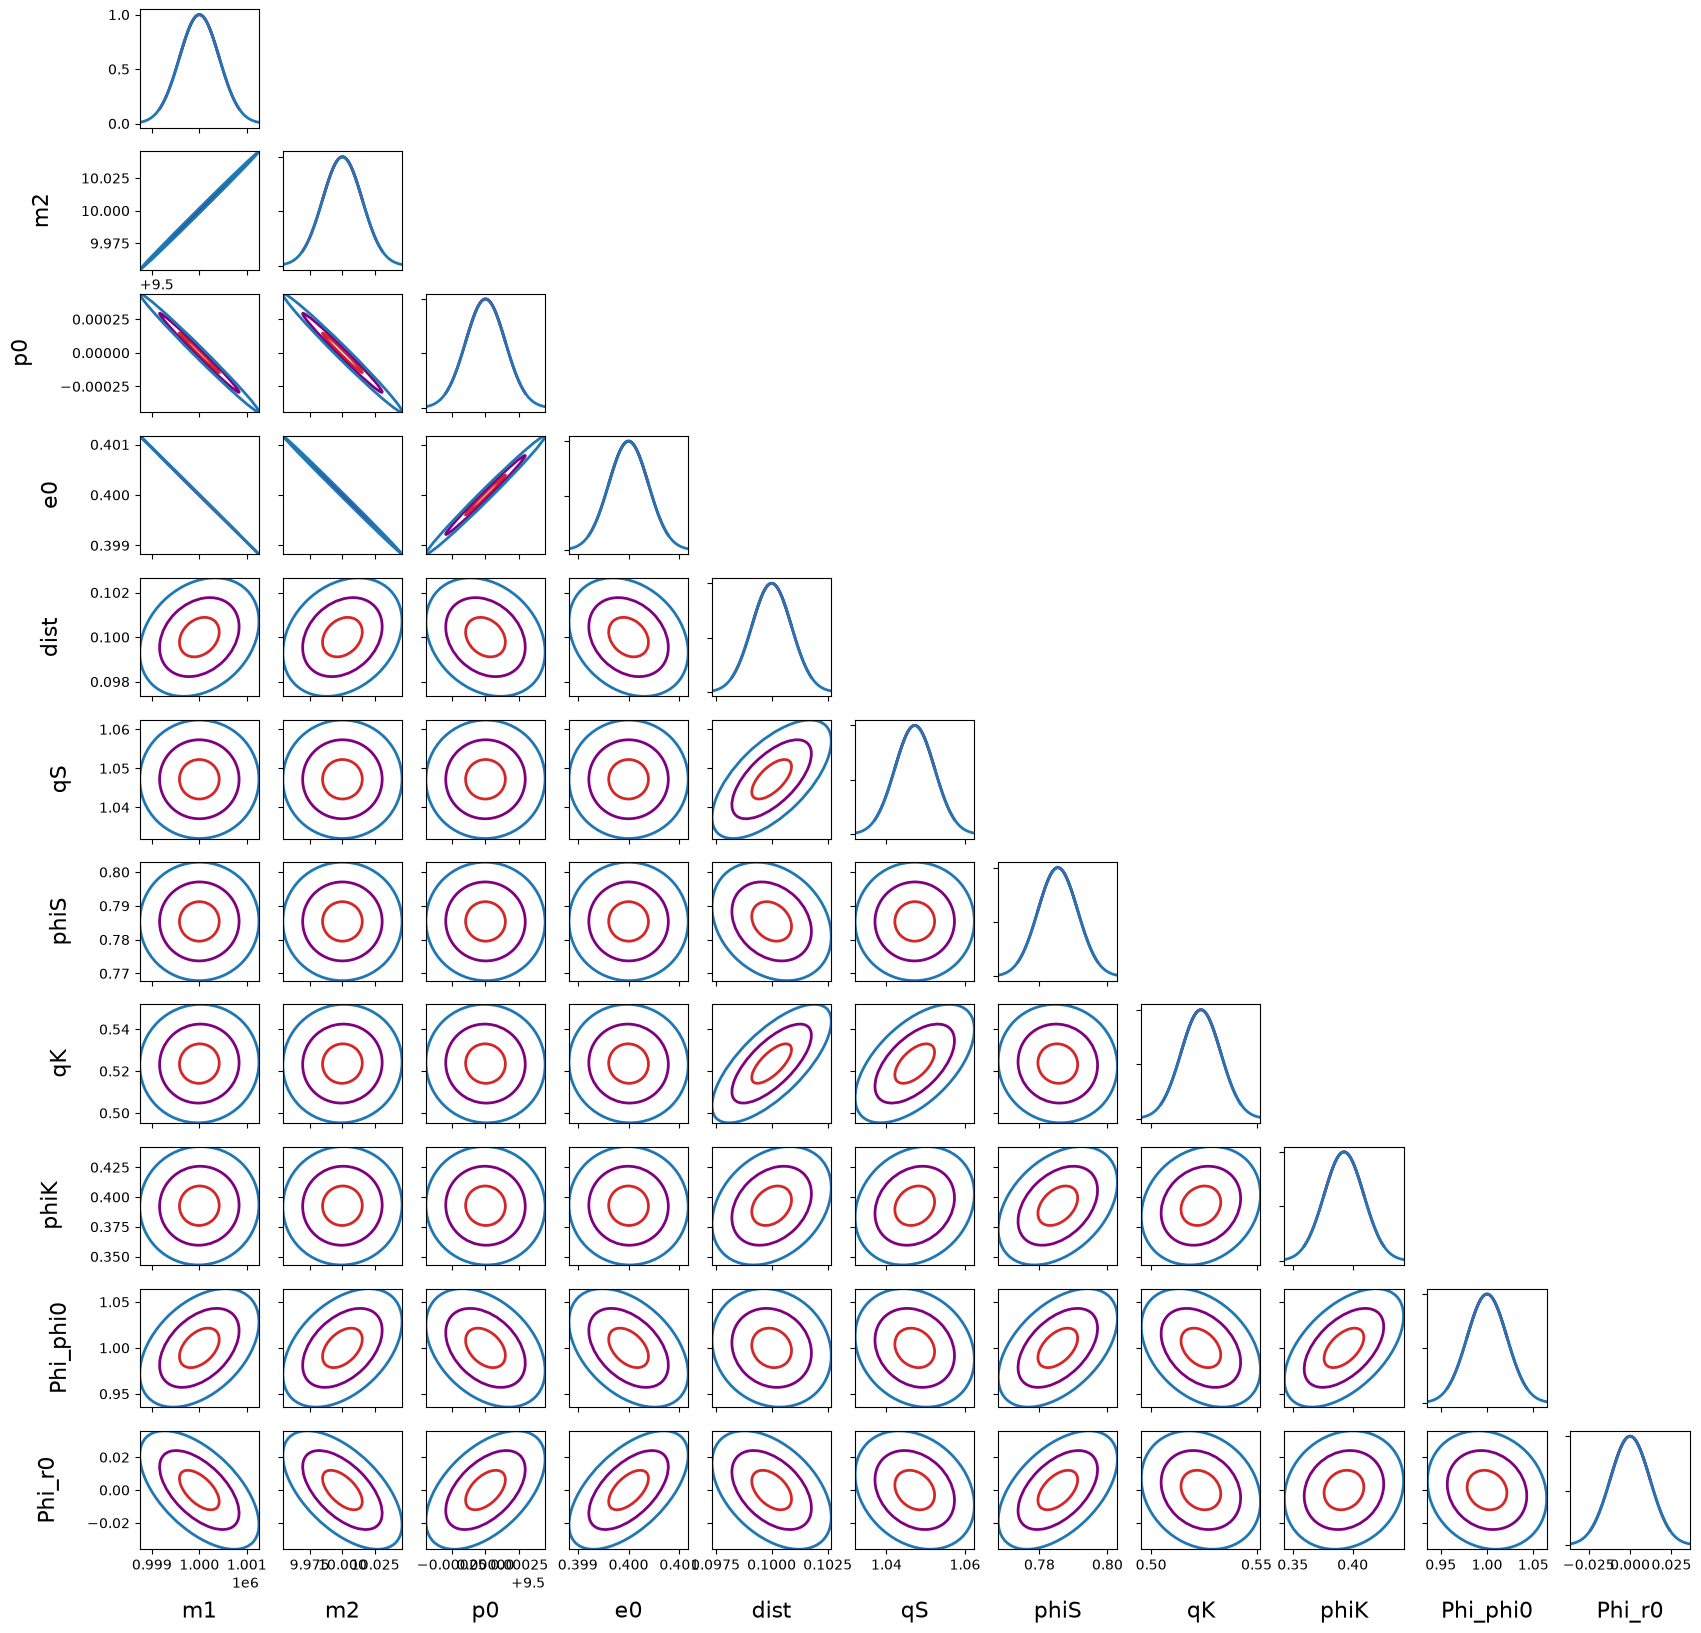

In [6]:
from stableemrifisher.plot import CovEllipsePlot

covariance = np.linalg.inv(Fisher)

fig, axs = plt.subplots(len(covariance),len(covariance), figsize=(20,20))

# 1-sigma contours (red)
ellipse_kwargs = dict(facecolor='None', edgecolor='tab:red', lw=2, n_std=1)
line_kwargs = dict(lw=2, color='tab:red')
fig, axs = CovEllipsePlot(covariance, wave_params=wave_params, param_names=param_names, fig=fig, axs=axs, ellipse_kwargs=ellipse_kwargs, line_kwargs=line_kwargs)

# 2-sigma contours (purple)
ellipse_kwargs = dict(facecolor='None', edgecolor='purple', lw=2, n_std=2)
line_kwargs = dict(lw=2, color='purple')
fig, axs = CovEllipsePlot(covariance, wave_params=wave_params, param_names=param_names, fig=fig, axs=axs, ellipse_kwargs=ellipse_kwargs, line_kwargs=line_kwargs)

# 3-sigma contours (blue)
ellipse_kwargs = dict(facecolor='None', edgecolor='tab:blue', lw=2, n_std=3)
line_kwargs = dict(lw=2, color='tab:blue')
fig, axs = CovEllipsePlot(covariance, wave_params=wave_params, param_names=param_names, fig=fig, axs=axs, ellipse_kwargs=ellipse_kwargs, line_kwargs=line_kwargs)

